# Phân tích khám phá dữ liệu (EDA) toàn diện: Data vs Legacy

Notebook này thực hiện EDA song song trên cả 2 nguồn dữ liệu: `data/` (bản mới, chi tiết) và `legacy/` (bản cũ, đầy đủ).
Quá trình được thực hiện trên Polars để tối ưu RAM.

In [1]:
# === Cell 1: Imports & Configuration ===
import os
from IPython.display import display, Markdown
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Apply seaborn style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.dpi'] = 100

from eda import (
    get_id_coverage,
    analyze_missing_legacy_insights,
    compare_metadata_datasets
)

# Resolve project root
try:
    _THIS_DIR = os.path.dirname(os.path.abspath(__file__))
except NameError:
    _THIS_DIR = os.getcwd()
_PROJECT_ROOT = os.path.dirname(os.path.dirname(_THIS_DIR))
BASE = os.path.join(_PROJECT_ROOT, "data", "raw", "vietnamese-legal-documents")
FILES = {
    "data/content":       os.path.join(BASE, "data", "content.parquet"),
    "data/metadata":      os.path.join(BASE, "data", "metadata.parquet"),
    "data/relationships": os.path.join(BASE, "data", "relationships.parquet"),
    "legacy/content":     os.path.join(BASE, "legacy", "content.parquet"),
    "legacy/metadata":    os.path.join(BASE, "legacy", "metadata.parquet"),
}

---
## 1. Tổng quan Dataset (Schema, Head, Basic Stats)

In [2]:
# === Cell 2: Schema & Size ===
display(Markdown("### 1.1. Cấu trúc và Kích thước các file"))
for name, path in FILES.items():
    if not os.path.exists(path):
        continue
    schema = pl.scan_parquet(path).collect_schema()
    n_rows = pl.scan_parquet(path).select(pl.len()).collect().item()
    display(Markdown(f"**{name}**: `{n_rows:,}` rows, `{len(schema)}` columns"))

### 1.1. Cấu trúc và Kích thước các file

**data/content**: `178,665` rows, `2` columns

**data/metadata**: `153,420` rows, `17` columns

**data/relationships**: `897,890` rows, `3` columns

**legacy/content**: `518,235` rows, `2` columns

**legacy/metadata**: `518,601` rows, `11` columns

In [3]:
# === Cell 3: Xem trước dữ liệu ===
display(Markdown("### 1.2. Dữ liệu mẫu (Head)"))
from IPython.display import HTML

for name, path in FILES.items():
    if not os.path.exists(path):
        continue
    display(Markdown(f"**{name}**"))
    df_head = pl.scan_parquet(path).head(3).collect().to_pandas()
    
    if "title" in df_head.columns:
        display(HTML(
            df_head.style
            .set_properties(**{"white-space": "nowrap"})
            .set_properties(subset=["title"], **{"white-space": "normal", "min-width": "400px", "max-width": "600px"})
            .set_table_styles([{"selector": "table", "props": [("width", "100%")]}])
            .to_html()
        ))
    else:
        if "content_html" in df_head.columns:
            df_head["content_html"] = df_head["content_html"].str.slice(0, 200) + "..."
        display(df_head)

### 1.2. Dữ liệu mẫu (Head)

**data/content**

,id,content_html
0,4260,"<table class=""detailcontent"" width=""100%"" bord..."
1,4266,"<table class=""detailcontent"" width=""100%"" bord..."
2,4262,"<table class=""detailcontent"" width=""100%"" bord..."


**data/metadata**

,id,title,so_ky_hieu,ngay_ban_hanh,loai_van_ban,ngay_co_hieu_luc,ngay_het_hieu_luc,nguon_thu_thap,ngay_dang_cong_bao,nganh,linh_vuc,co_quan_ban_hanh,chuc_danh,nguoi_ky,pham_vi,thong_tin_ap_dung,tinh_trang_hieu_luc
0,72,Sắc lệnh quy định liên hệ giữa UBKCHC và các cơ quan chuyên môn,103/SL,05/06/1950,Sắc lệnh,20/06/1950,nan,Công báo số 7/1950;,...,nan,nan,Chủ tịch nước,Chủ tịch nước,Hồ Chí Minh,nan,nan,Hết hiệu lực toàn bộ
1,4260,Về việc chuyển giao nhiệm vụ quản lý Nhà nước về đất lâm nghiệp từ Sở Nông nghiệp và Phát triển Nông thôn và Chi cục kiểm lâm tỉnh sang Sở Địa chính để quản lý,87/1999/QĐ-UB,12/07/1999,Quyết định,12/07/1999,nan,STP tỉnh Lâm Đồng;,...,nan,nan,UBND tỉnh Lâm Đồng,Q.Chủ tịch,Đặng Đức Lợi,Lâm Đồng,nan,Còn hiệu lực
2,4280,Về viẹc quản lý và quy định thống nhất phí chợ trên địa bàn tỉnh Lâm Đồng,157/1999/QĐ-UB,19/11/1999,Quyết định,19/11/1999,nan,STP tỉnh Lâm Đồng;,...,Tài chính,nan,UBND tỉnh Lâm Đồng,Phó Chủ tịch,Trương Thành Trung,Lâm Đồng,nan,Còn hiệu lực


...

,doc_id,other_doc_id,relationship
0,4260,10420,Văn bản căn cứ
1,4280,7245,Văn bản căn cứ
2,4263,10420,Văn bản căn cứ


**legacy/content**

,id,content
0,693036,HỘI ĐỒNG BẦU CỬ QUỐC GIA | CỘNG HÒA XÃ HỘI CH...
1,680604,ỦY BAN NHÂN DÂN TỈNH QUẢNG TRỊ | CỘNG HÒA XÃ ...
2,694312,ỦY BAN NHÂN DÂN THÀNH PHỐ HỒ CHÍ MINH | CỘNG ...


**legacy/metadata**

,id,document_number,title,legal_type,legal_sectors,issuing_authority,issuance_date,effect_date,effectless_date,effect_status,signers
0,693036,115/NQ-HĐBCQG,Nghị quyết 115/NQ-HĐBCQG năm 2026 hướng dẫn xử lý trường hợp khuyết người ứng cử đại biểu Hội đồng nhân dân vì lý do bất khả kháng do Hội đồng bầu cử Quốc gia ban hành,Resolution,Administrative apparatus,Hội đồng bầu cử quốc gia,2026-01-29,2026-01-29,nan,In effect,Trần Thanh Mẫn:2140
1,680604,34/2025/QĐ-UBND,"Quyết định 34/2025/QĐ-UBND năm 2025 quy định khoảng cách và địa bàn làm căn cứ xác định học sinh, học viên không thể đến trường và trở về nhà trong ngày; danh mục trang cấp đồ dùng cá nhân, học phẩm cho học sinh trường phổ thông dân tộc nội trú, cơ sở giáo dục phổ thông được cấp có thẩm quyền giao thực hiện nhiệm vụ giáo dục học sinh dân tộc nội trú trên địa bàn tỉnh Quảng Trị",Decision,Education,Tỉnh Quảng Trị,2025-10-31,2025-11-09,nan,In effect,Hoàng Xuân Tân:7612
2,694312,06/2026/QĐ-UBND,"Quyết định 06/2026/QĐ-UBND quy định phân cấp quản lý, bảo vệ, thực hiện biện pháp ngăn chặn và xử lý hành vi lấn chiếm đất dành cho đường sắt trên địa bàn Thành phố Hồ Chí Minh",Decision,"Real estate, Transport",Thành phố Hồ Chí Minh,2026-02-09,2026-02-20,nan,In effect,Bùi Xuân Cường:4780


---
## 2. So sánh Phân bố nhãn (Label Distribution)

### 2.1. Phân bố Nhãn (Data vs Legacy)

**🗓️ Column mapping:**

data/ (Việt),legacy/ (Eng)
str,str
"""so_ky_hieu""","""document_number"""
"""title""","""title"""
"""loai_van_ban""","""legal_type"""
"""co_quan_ban_hanh""","""issuing_authority"""
"""ngay_ban_hanh""","""issuance_date"""
"""ngay_co_hieu_luc""","""effect_date"""
"""ngay_het_hieu_luc""","""effectless_date"""
"""tinh_trang_hieu_luc""","""effect_status"""
"""nguoi_ky""","""signers"""


Metric,data/metadata,legacy/metadata
str,str,str
"""Tổng số dòng""","""153,420""","""518,601"""
"""Số cột""","""17""","""11"""
"""Cột chỉ có ở data/""","""nguon_thu_thap, ngay_dang_cong…","""—"""
"""Cột chỉ có ở legacy/""","""—""","""legal_sectors"""
"""ID overlap""","""116,223""","""116,223"""
"""ID chỉ có ở bộ này""","""37,197""","""402,378"""


### 🏷️ loai_van_ban vs legal_type

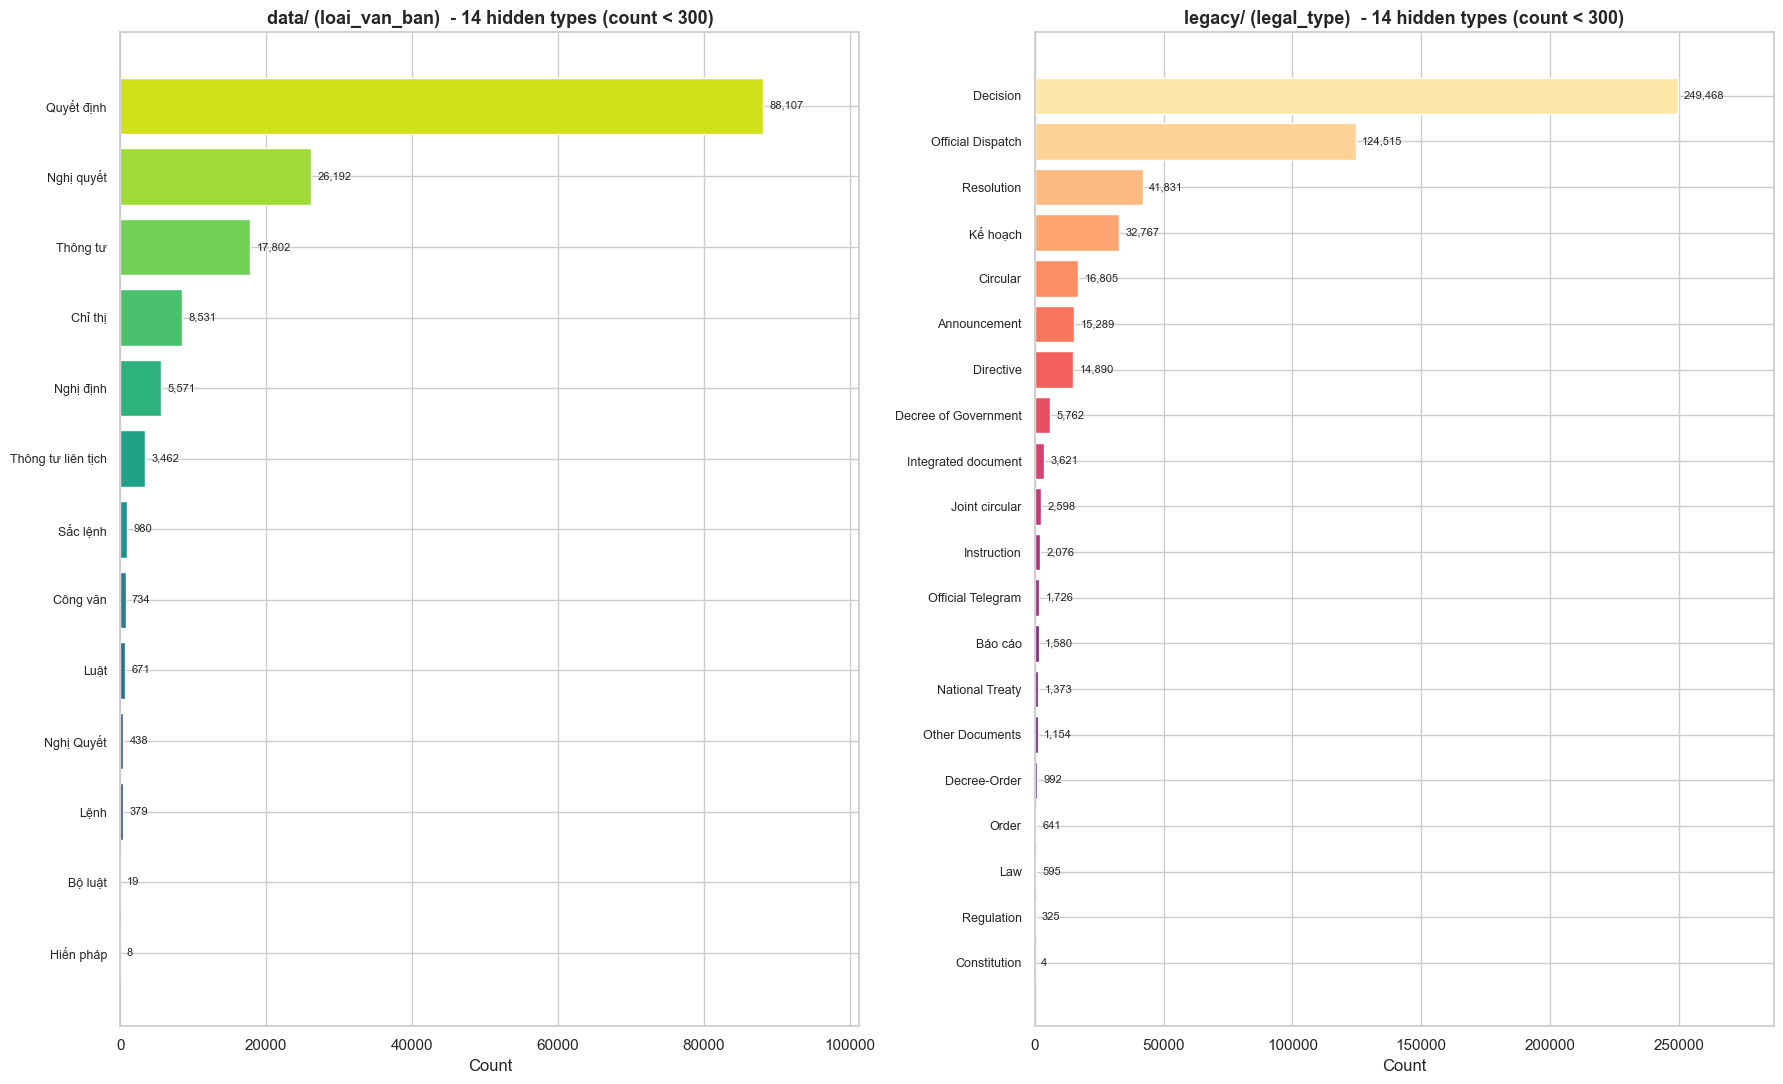

### 🏷️ tinh_trang_hieu_luc vs effect_status

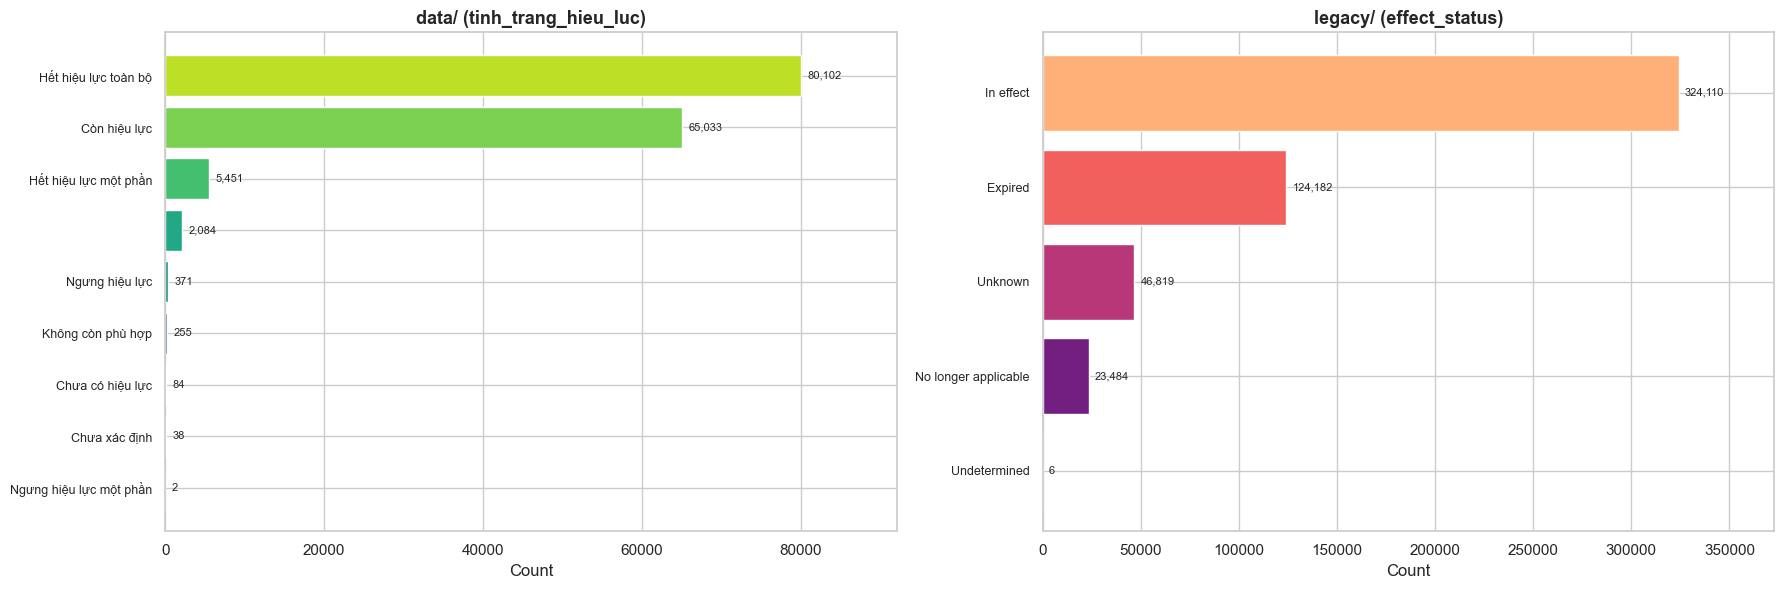

In [4]:
# === Cell 4: Phân bố loại văn bản & Tình trạng hiệu lực ===
display(Markdown("### 2.1. Phân bố Nhãn (Data vs Legacy)"))

mcmp = compare_metadata_datasets(FILES["data/metadata"], FILES["legacy/metadata"])

# Bảng column mapping
map_rows = [{"data/ (Việt)": k, "legacy/ (Eng)": v} for k, v in mcmp["col_map"].items()]
display(Markdown("**🗓️ Column mapping:**"))
display(pl.DataFrame(map_rows))

meta_summary = [
    {"Metric": "Tổng số dòng", "data/metadata": f'{mcmp["n_data"]:,}', "legacy/metadata": f'{mcmp["n_legacy"]:,}'},
    {"Metric": "Số cột", "data/metadata": str(len(mcmp["schema_data"])), "legacy/metadata": str(len(mcmp["schema_legacy"]))},
    {"Metric": "Cột chỉ có ở data/", "data/metadata": ", ".join(mcmp["data_only_cols"]) or "—", "legacy/metadata": "—"},
    {"Metric": "Cột chỉ có ở legacy/", "data/metadata": "—", "legacy/metadata": ", ".join(mcmp["legacy_only_cols"]) or "—"},
    {"Metric": "ID overlap", "data/metadata": f'{mcmp["n_overlap"]:,}', "legacy/metadata": f'{mcmp["n_overlap"]:,}'},
    {"Metric": "ID chỉ có ở bộ này", "data/metadata": f'{mcmp["n_only_data"]:,}', "legacy/metadata": f'{mcmp["n_only_legacy"]:,}'},
]
display(pl.DataFrame(meta_summary))

# Categories to always keep even if count < threshold (notable legal types)
_KEEP_ALWAYS = {"Bộ luật", "Hiến pháp", "Constitution", "Code"}
_MIN_COUNT = 300  # hide categories below this threshold

for pair_name, pair_data in mcmp["cat_comparisons"].items():
    display(Markdown(f"### 🏷️ {pair_name}"))

    # For loai_van_ban vs legal_type: filter small categories
    is_type_chart = "loai_van_ban" in pair_name

    filtered_pair = {}
    for side_key, vc_df in [("data", pair_data["data"]), ("legacy", pair_data["legacy"])]:
        pdf = vc_df.to_pandas()
        if is_type_chart:
            n_before = len(pdf)
            mask = (pdf["count"] >= _MIN_COUNT) | (pdf["value"].isin(_KEEP_ALWAYS))
            pdf = pdf[mask]
            n_hidden = n_before - len(pdf)
        else:
            n_hidden = 0
        filtered_pair[side_key] = (pdf, n_hidden)

    # Dynamic height: scale based on max number of categories across both sides
    n_max = max(len(filtered_pair["data"][0]), len(filtered_pair["legacy"][0]))
    fig_h = max(6, n_max * 0.45 + 2)  # at least 6, ~0.45 inch per category
    fig, axes = plt.subplots(1, 2, figsize=(18, fig_h))

    for i, (label, side_key) in enumerate([("data/", "data"), ("legacy/", "legacy")]):
        pdf, n_hidden = filtered_pair[side_key]
        pdf = pdf.sort_values("count", ascending=True)
        axes[i].barh(pdf["value"], pdf["count"],
                      color=sns.color_palette("viridis" if i == 0 else "magma", len(pdf)))
        subtitle = f"{label} ({pair_name.split(' vs ')[i]})"
        if n_hidden > 0:
            subtitle += f"  - {n_hidden} hidden types (count < {_MIN_COUNT})"
        axes[i].set_title(subtitle, fontsize=13, fontweight="bold")
        axes[i].set_xlabel("Count")
        axes[i].tick_params(axis="y", labelsize=9)
        max_cnt = max(pdf["count"])
        for j, (_, row) in enumerate(pdf.iterrows()):
            axes[i].text(row["count"] + max_cnt * 0.01, j,
                         f'{row["count"]:,}', va="center", fontsize=8)
        axes[i].set_xlim(right=max_cnt * 1.15)

    plt.tight_layout()
    plt.show()

---
## 3. Phân tích Thời gian (Temporal Analysis)

### 3.1. So sánh số lượng văn bản qua các năm

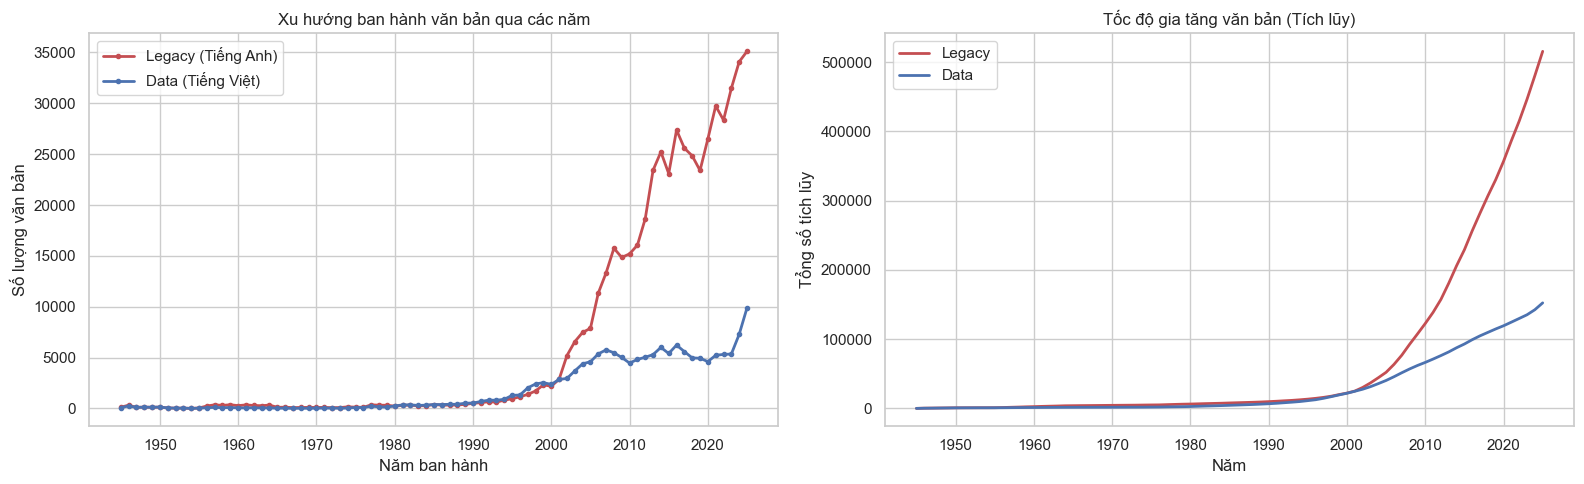

> **Nhận xét**: Tập `legacy` có độ phủ thời gian rộng hơn và lưu trữ nhiều văn bản cũ hơn đáng kể so với `data`.

In [5]:
# === Cell 5: So sánh xu hướng ban hành theo năm ===
display(Markdown("### 3.1. So sánh số lượng văn bản qua các năm"))

# Lấy dữ liệu Data
df_time_data = pl.scan_parquet(FILES["data/metadata"]).select("ngay_ban_hanh").collect()
parsed_data = df_time_data.with_columns(
    pl.col("ngay_ban_hanh").str.to_date("%d/%m/%Y", strict=False).alias("date")
).filter(pl.col("date").is_not_null())
yearly_data = (
    parsed_data.with_columns(pl.col("date").dt.year().alias("year"))
    .group_by("year").agg(pl.len().alias("count")).sort("year")
    .filter((pl.col("year") >= 1945) & (pl.col("year") <= 2025))
    .to_pandas()
)

# Lấy dữ liệu Legacy
df_time_legacy = pl.scan_parquet(FILES["legacy/metadata"]).select("issuance_date").collect()
parsed_legacy = df_time_legacy.with_columns(
    pl.col("issuance_date").str.to_date("%Y-%m-%d", strict=False).alias("date")
).filter(pl.col("date").is_not_null())
yearly_legacy = (
    parsed_legacy.with_columns(pl.col("date").dt.year().alias("year"))
    .group_by("year").agg(pl.len().alias("count")).sort("year")
    .filter((pl.col("year") >= 1945) & (pl.col("year") <= 2025))
    .to_pandas()
)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Timeline bar chart overlap
axes[0].plot(yearly_legacy["year"], yearly_legacy["count"], label="Legacy (Tiếng Anh)", color="#C44E52", lw=2, marker='.')
axes[0].plot(yearly_data["year"], yearly_data["count"], label="Data (Tiếng Việt)", color="#4C72B0", lw=2, marker='.')
axes[0].set_xlabel("Năm ban hành")
axes[0].set_ylabel("Số lượng văn bản")
axes[0].set_title("Xu hướng ban hành văn bản qua các năm")
axes[0].legend()

# Cumulative
yearly_data_sorted = yearly_data.sort_values("year")
yearly_data_sorted["cumsum"] = yearly_data_sorted["count"].cumsum()
yearly_legacy_sorted = yearly_legacy.sort_values("year")
yearly_legacy_sorted["cumsum"] = yearly_legacy_sorted["count"].cumsum()

axes[1].plot(yearly_legacy_sorted["year"], yearly_legacy_sorted["cumsum"], label="Legacy", color="#C44E52", lw=2)
axes[1].plot(yearly_data_sorted["year"], yearly_data_sorted["cumsum"], label="Data", color="#4C72B0", lw=2)
axes[1].set_xlabel("Năm")
axes[1].set_ylabel("Tổng số tích lũy")
axes[1].set_title("Tốc độ gia tăng văn bản (Tích lũy)")
axes[1].legend()

plt.tight_layout()
plt.show()

display(Markdown("> **Nhận xét**: Tập `legacy` có độ phủ thời gian rộng hơn và lưu trữ nhiều văn bản cũ hơn đáng kể so với `data`."))

---
## 4. Phân tích Top Thực thể (Top Entities)

### 4.1. So sánh Top Thực thể (Data vs Legacy)

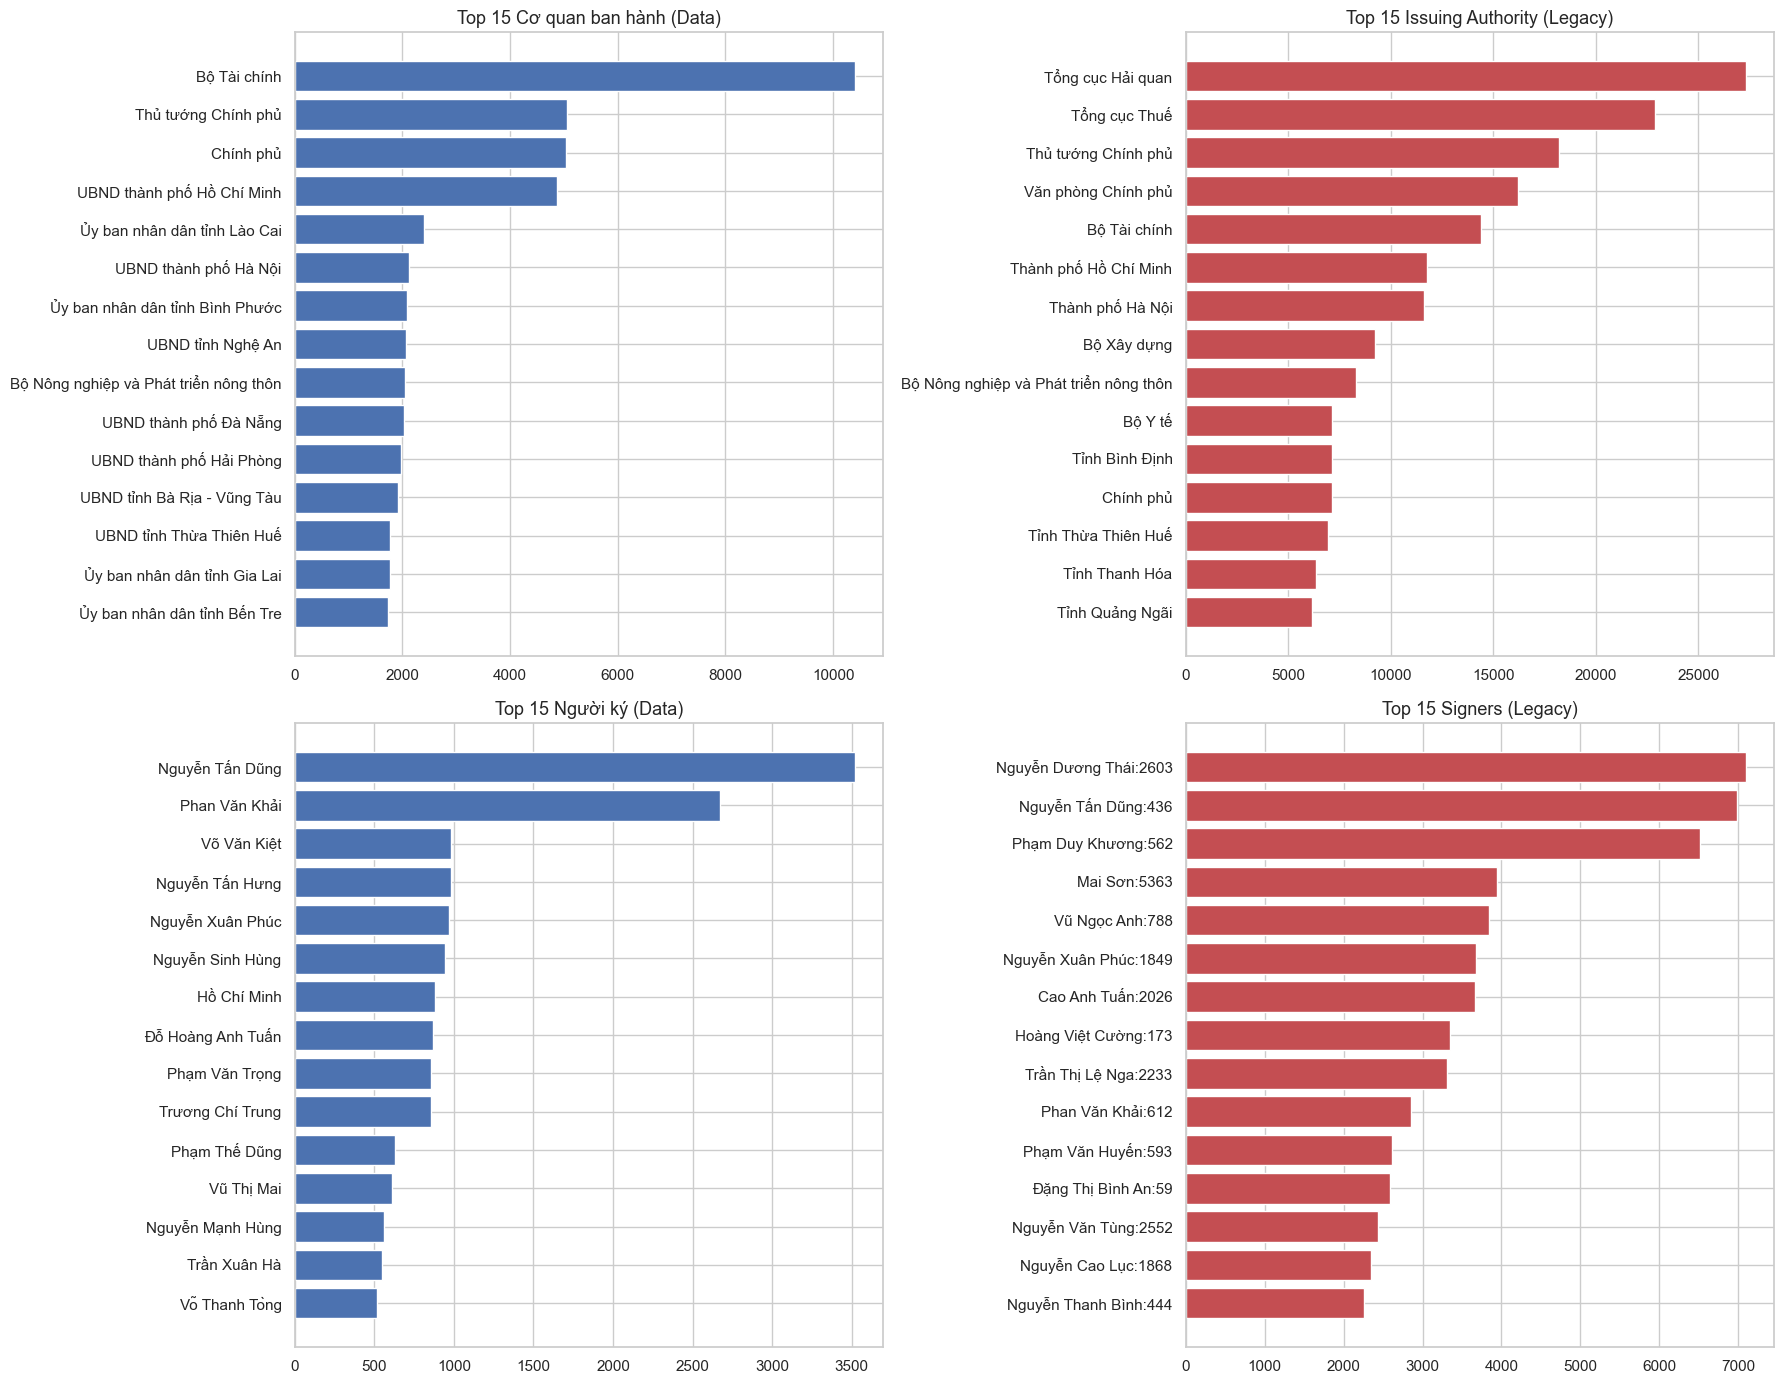

In [6]:
# === Cell 6: Top Cơ quan ban hành & Người ký ===
display(Markdown("### 4.1. So sánh Top Thực thể (Data vs Legacy)"))

fig, axes = plt.subplots(2, 2, figsize=(18, 14))

# -- Cơ quan ban hành --
# Data
auths_data = pl.scan_parquet(FILES["data/metadata"]).select("co_quan_ban_hanh").collect().to_series().drop_nulls().value_counts(sort=True).head(15).to_pandas()
auths_data.columns = ["auth", "count"]
auths_data = auths_data.sort_values("count", ascending=True)
axes[0, 0].barh(auths_data["auth"], auths_data["count"], color="#4C72B0")
axes[0, 0].set_title("Top 15 Cơ quan ban hành (Data)", fontsize=13)

# Legacy
auths_leg = pl.scan_parquet(FILES["legacy/metadata"]).select("issuing_authority").collect().to_series().drop_nulls().value_counts(sort=True).head(15).to_pandas()
auths_leg.columns = ["auth", "count"]
auths_leg = auths_leg.sort_values("count", ascending=True)
axes[0, 1].barh(auths_leg["auth"], auths_leg["count"], color="#C44E52")
axes[0, 1].set_title("Top 15 Issuing Authority (Legacy)", fontsize=13)

# -- Người ký --
# Data
sign_data = pl.scan_parquet(FILES["data/metadata"]).select("nguoi_ky").collect().to_series().drop_nulls().value_counts(sort=True).head(15).to_pandas()
sign_data.columns = ["sign", "count"]
sign_data = sign_data.sort_values("count", ascending=True)
axes[1, 0].barh(sign_data["sign"], sign_data["count"], color="#4C72B0")
axes[1, 0].set_title("Top 15 Người ký (Data)", fontsize=13)

# Legacy
sign_leg = pl.scan_parquet(FILES["legacy/metadata"]).select("signers").collect().to_series().drop_nulls().value_counts(sort=True).head(15).to_pandas()
sign_leg.columns = ["sign", "count"]
sign_leg = sign_leg.sort_values("count", ascending=True)
axes[1, 1].barh(sign_leg["sign"], sign_leg["count"], color="#C44E52")
axes[1, 1].set_title("Top 15 Signers (Legacy)", fontsize=13)

plt.tight_layout()
plt.show()

---
## 5. Phân tích Dữ liệu Phi cấu trúc (Unstructured Data)

### 5.1. So sánh độ dài văn bản (Data HTML vs Legacy Plain Text)

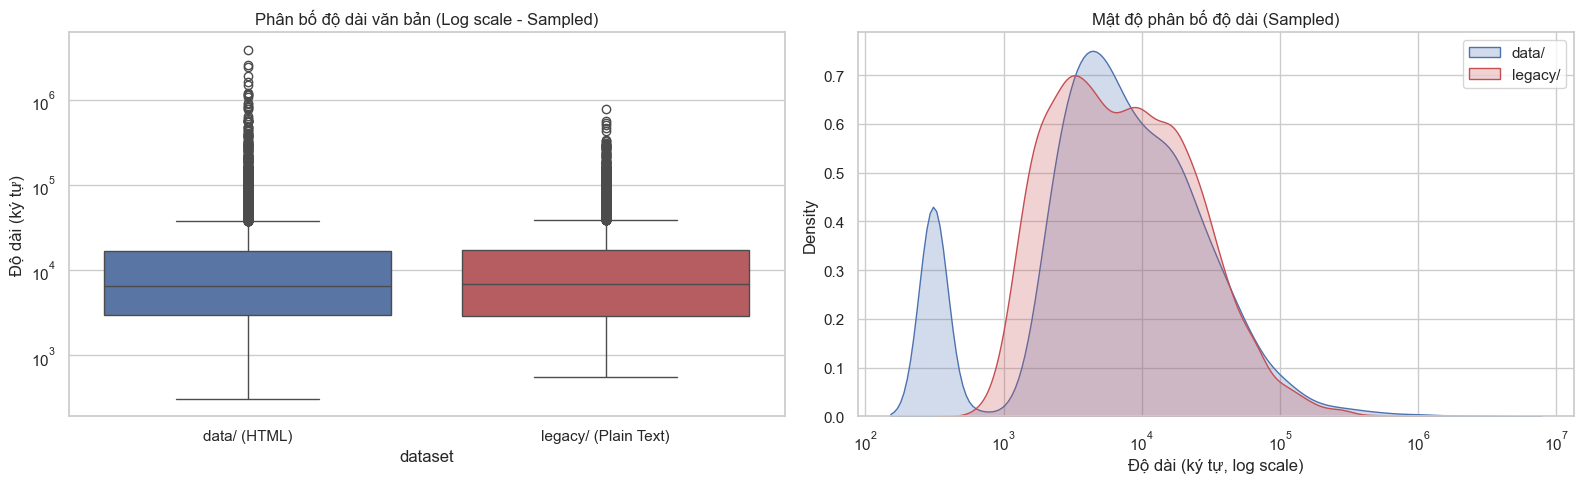

In [7]:
# === Cell 7: So sánh Content Length ===
display(Markdown("### 5.1. So sánh độ dài văn bản (Data HTML vs Legacy Plain Text)"))

def get_content_length_stats(path: str, col_name: str):
    len_series = pl.scan_parquet(path).select(pl.col(col_name).str.len_chars().alias("length")).collect().to_series()
    return len_series

data_len_s = get_content_length_stats(FILES["data/content"], "content_html")
legacy_len_s = get_content_length_stats(FILES["legacy/content"], "content")

# Random sample to plot KDE safely without crashing RAM
data_sample = data_len_s.sample(min(10000, len(data_len_s)), seed=42).to_pandas()
data_sample = data_sample.to_frame(name="length")
data_sample["dataset"] = "data/ (HTML)"

legacy_sample = legacy_len_s.sample(min(10000, len(legacy_len_s)), seed=42).to_pandas()
legacy_sample = legacy_sample.to_frame(name="length")
legacy_sample["dataset"] = "legacy/ (Plain Text)"

comb_pd = pl.concat([pl.DataFrame(data_sample), pl.DataFrame(legacy_sample)]).to_pandas()

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Plot 1: Boxplot
sns.boxplot(data=comb_pd, x="dataset", y="length", ax=axes[0], hue="dataset", palette=["#4C72B0", "#C44E52"], legend=False)
axes[0].set_yscale("log")
axes[0].set_title("Phân bố độ dài văn bản (Log scale - Sampled)")
axes[0].set_ylabel("Độ dài (ký tự)")

# Plot 2: Histogram KDE
sns.kdeplot(data=data_sample, x="length", log_scale=True, ax=axes[1], color="#4C72B0", fill=True, label="data/")
sns.kdeplot(data=legacy_sample, x="length", log_scale=True, ax=axes[1], color="#C44E52", fill=True, label="legacy/")
axes[1].set_title("Mật độ phân bố độ dài (Sampled)")
axes[1].set_xlabel("Độ dài (ký tự, log scale)")
axes[1].legend()

plt.tight_layout()
plt.show()

---
## 6. Kiểm tra Chất lượng Dữ liệu (Data Quality & Coverage)

### 6.1. Tỷ lệ Missing Values (NULL Heatmap)

Text(0.5, 1.0, 'Tỷ lệ NULL (%) theo cột × dataset')

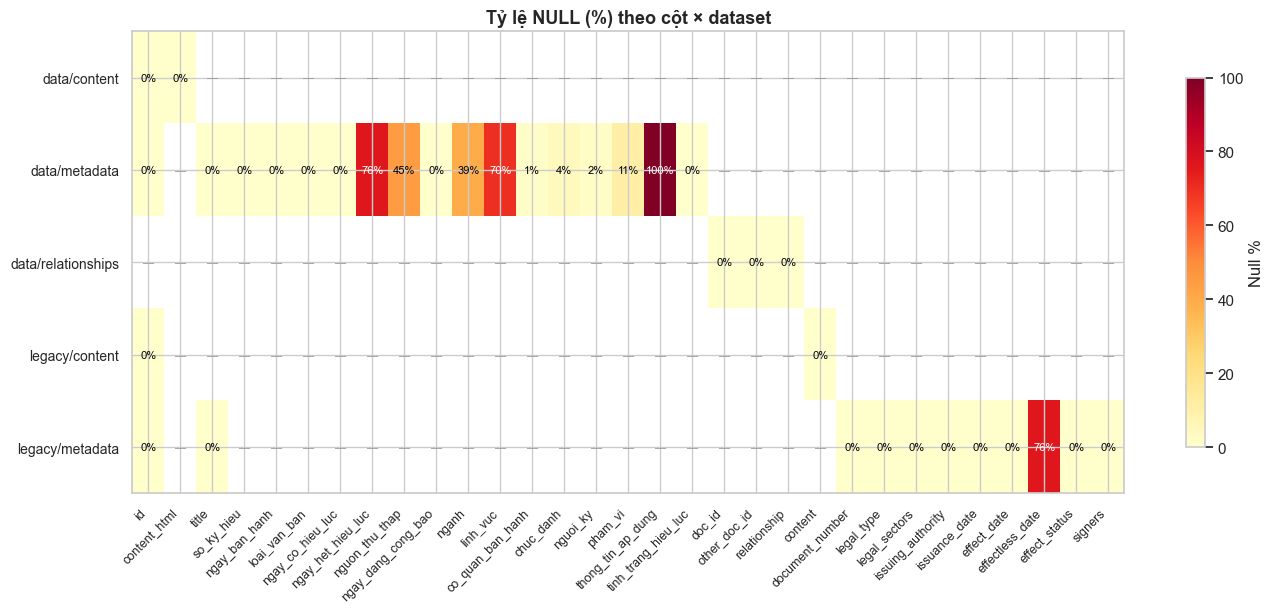

In [8]:
# === Cell 8: Null Heatmap ===
display(Markdown("### 6.1. Tỷ lệ Missing Values (NULL Heatmap)"))

quality_data = {}
for name, path in FILES.items():
    if not os.path.exists(path):
        continue
    schema = pl.scan_parquet(path).collect_schema()
    total_q = pl.scan_parquet(path).select(pl.len()).collect().item()
    null_pcts = {}
    null_exprs = [pl.col(col).null_count().alias(col) for col in schema.names()]
    null_counts = pl.scan_parquet(path).select(null_exprs).collect()
    for col in schema.names():
        null_pcts[col] = round(null_counts[col][0] / total_q * 100, 1)
    quality_data[name] = null_pcts

# Build matrix
all_cols = []
for v in quality_data.values():
    for c in v:
        if c not in all_cols:
            all_cols.append(c)

matrix = []
ds_labels = []
for ds_name, cols_dict in quality_data.items():
    row = [cols_dict.get(c, float("nan")) for c in all_cols]
    matrix.append(row)
    ds_labels.append(ds_name)

fig, ax = plt.subplots(figsize=(16, 6))
mat = np.array(matrix)
im = ax.imshow(mat, cmap="YlOrRd", aspect="auto", vmin=0, vmax=100)

ax.set_xticks(range(len(all_cols)))
ax.set_xticklabels(all_cols, rotation=45, ha="right", fontsize=9)
ax.set_yticks(range(len(ds_labels)))
ax.set_yticklabels(ds_labels, fontsize=10)

# Annotate cells
for i in range(len(ds_labels)):
    for j in range(len(all_cols)):
        val = mat[i, j]
        if np.isnan(val):
            ax.text(j, i, "—", ha="center", va="center", fontsize=8, color="#999")
        else:
            color = "white" if val > 50 else "black"
            ax.text(j, i, f"{val:.0f}%", ha="center", va="center", fontsize=8, color=color)

plt.colorbar(im, ax=ax, label="Null %", shrink=0.8)
ax.set_title("Tỷ lệ NULL (%) theo cột × dataset", fontsize=13, fontweight="bold")

### 6.2. Mức độ bao phủ ID (ID Coverage)

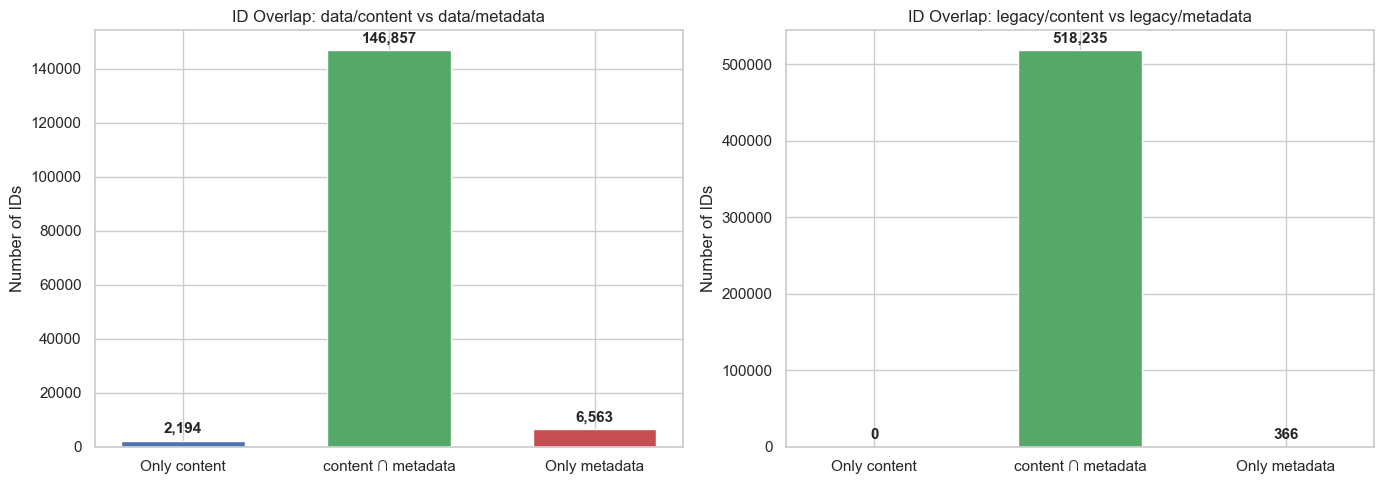

In [9]:
# === Cell 9: ID Coverage ===
display(Markdown("### 6.2. Mức độ bao phủ ID (ID Coverage)"))

cov = get_id_coverage(FILES["data/content"], FILES["data/metadata"], FILES["data/relationships"])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Content vs Metadata (data/)
labels1 = ["Only content", "content \u2229 metadata", "Only metadata"]
vals1 = [cov["content_not_in_metadata"], cov["content_in_metadata"], cov["metadata_not_in_content"]]
colors1 = ["#4C72B0", "#55A868", "#C44E52"]
bars1 = axes[0].bar(labels1, vals1, color=colors1, edgecolor="white", width=0.6)
axes[0].set_title("ID Overlap: data/content vs data/metadata")
axes[0].set_ylabel("Number of IDs")
for bar, v in zip(bars1, vals1):
    axes[0].text(bar.get_x() + bar.get_width()/2, v + max(vals1)*0.02,
                 f"{v:,}", ha="center", fontsize=11, fontweight="bold")

# Legacy content vs metadata
try:
    # Try using Int64 to save memory if possible
    leg_c_raw = pl.scan_parquet(FILES["legacy/content"]).select(pl.col("id")).collect().to_series()
    try:
        leg_c = set(leg_c_raw.cast(pl.Int64).to_list())
    except:
        leg_c = set(leg_c_raw.to_list())
    
    leg_m_raw = pl.scan_parquet(FILES["legacy/metadata"]).select(pl.col("id")).collect().to_series()
    try:
        leg_m = set(leg_m_raw.cast(pl.Int64).to_list())
    except:
        leg_m = set(leg_m_raw.to_list())
except Exception:
    leg_c = set()
    leg_m = set()

val_c_only = len(leg_c - leg_m)
val_overlap = len(leg_c & leg_m)
val_m_only = len(leg_m - leg_c)

labels2 = ["Only content", "content \u2229 metadata", "Only metadata"]
vals2 = [val_c_only, val_overlap, val_m_only]
bars2 = axes[1].bar(labels2, vals2, color=colors1, edgecolor="white", width=0.6)
axes[1].set_title("ID Overlap: legacy/content vs legacy/metadata")
axes[1].set_ylabel("Number of IDs")
for bar, v in zip(bars2, vals2):
    axes[1].text(bar.get_x() + bar.get_width()/2, v + max(vals2)*0.02,
                 f"{v:,}", ha="center", fontsize=11, fontweight="bold")

plt.tight_layout()
plt.show()

---
## 7. Phân tích Mạng lưới (Network Analysis)
> **Lưu ý**: Tập `legacy` không chứa thông tin về quan hệ giữa các văn bản. Do đó, phần này chỉ được áp dụng trên tập `data`.

### 7.1. Bậc kết nối (Degree Distribution) - Chỉ tập Data

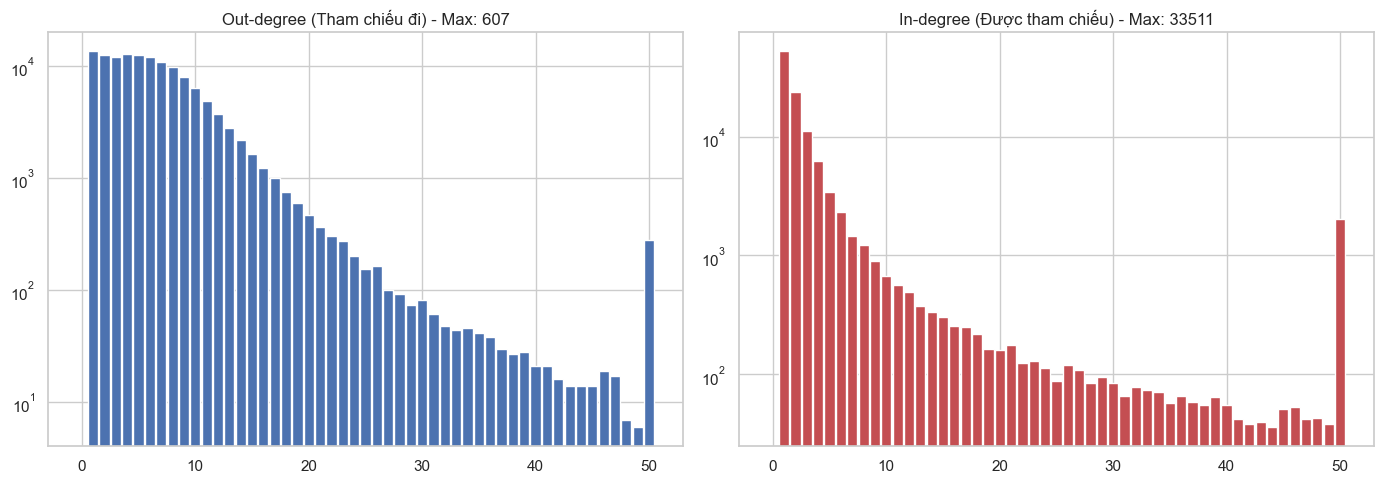

In [10]:
# === Cell 10: Phân tích Degree (Data only) ===
display(Markdown("### 7.1. Bậc kết nối (Degree Distribution) - Chỉ tập Data"))

out_deg = pl.scan_parquet(FILES["data/relationships"]).group_by("doc_id").agg(pl.len().alias("out_degree")).collect()
in_deg = pl.scan_parquet(FILES["data/relationships"]).group_by("other_doc_id").agg(pl.len().alias("in_degree")).collect()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
out_s = out_deg["out_degree"]
out_np = out_s.clip(0, 50).to_numpy()
out_bins = np.arange(0, 52)
out_hist, _ = np.histogram(out_np, bins=out_bins)
axes[0].bar(out_bins[:-1], out_hist, width=0.9, color="#4C72B0")
axes[0].set_yscale("log")
axes[0].set_title(f"Out-degree (Tham chiếu đi) - Max: {int(out_s.max())}")

in_s = in_deg["in_degree"]
in_np = in_s.clip(0, 50).to_numpy()
in_hist, _ = np.histogram(in_np, bins=out_bins)
axes[1].bar(out_bins[:-1], in_hist, width=0.9, color="#C44E52")
axes[1].set_yscale("log")
axes[1].set_title(f"In-degree (Được tham chiếu) - Max: {int(in_s.max())}")

plt.tight_layout()
plt.show()

---
## 8. Phân tích Chuyên sâu: Khoảng trống Dữ liệu (Data Gap)

### 8.1. Insight: 365,000+ văn bản bị rò rỉ khỏi tập `data/`

- **Tổng số văn bản chỉ có ở legacy:** `402,378`

- **Số văn bản TRỌNG YẾU bị thiếu trong data (Hiến pháp, Bộ luật, Luật, Pháp lệnh):** `449`

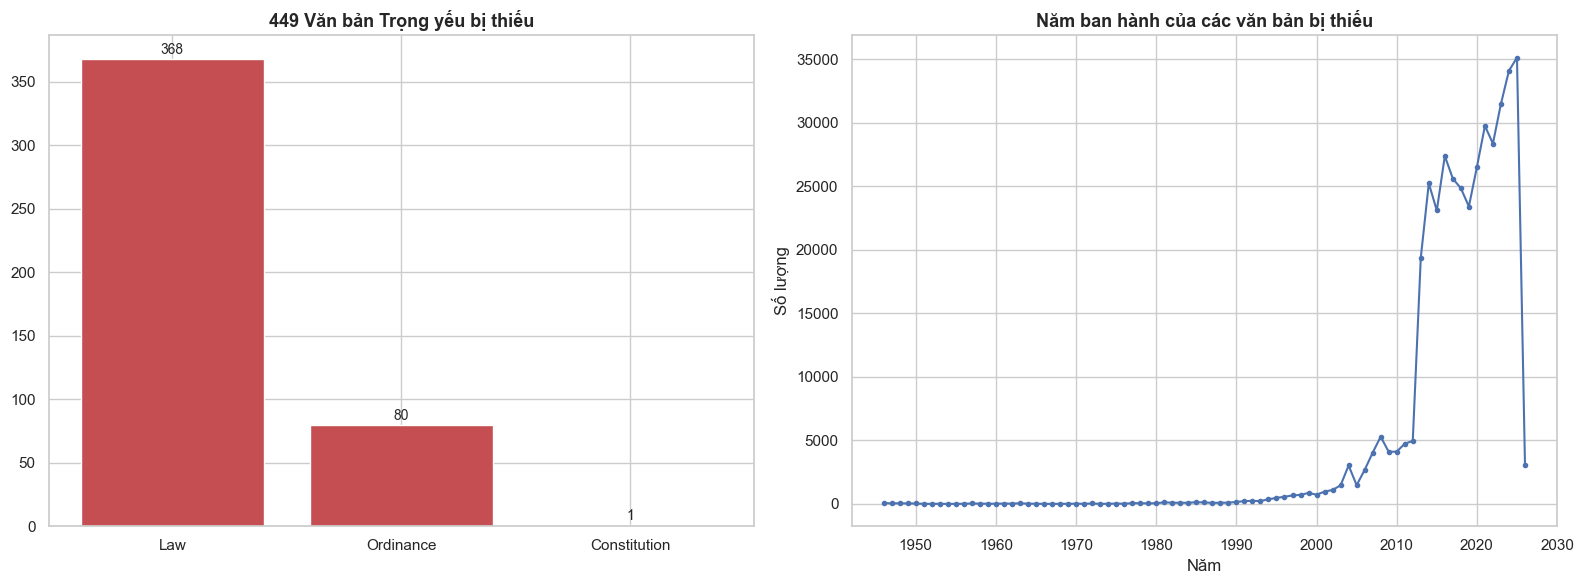

**Top 15 văn bản trọng yếu bị thiếu:**

id,document_number,title,legal_type,issuance_date
i64,str,str,str,str
675267,"""131/2025/QH15""","""Luật Sở hữu trí tuệ sửa đổi 20…","""Law""","""2025-12-10"""
586814,"""112/2025/QH15""","""Luật Quy hoạch 2025""","""Law""","""2025-12-10"""
580594,"""67/2025/QH15""","""Luật Thuế thu nhập doanh nghiệ…","""Law""","""2025-06-14"""
298370,"""89/2015/QH13""","""Luật thống kê 2015""","""Law""","""2015-11-23"""
298374,"""95/2015/QH13""","""Bộ luật hàng hải Việt Nam 2015""","""Law""","""2015-11-25"""
…,…,…,…,…
588810,"""37/2024/QH15""","""Luật Đấu giá tài sản sửa đổi 2…","""Law""","""2024-06-27"""
667661,"""105/2025/QH15""","""Luật Giám định tư pháp 2025""","""Law""","""2025-12-05"""
679014,"""128/2025/QH15""","""Luật Thi hành tạm giữ, tạm gia…","""Law""","""2025-12-10"""


In [11]:
# === Cell 11: Sự thiếu hụt văn bản trọng yếu ===
display(Markdown("### 8.1. Insight: 365,000+ văn bản bị rò rỉ khỏi tập `data/`"))

legacy_insights = analyze_missing_legacy_insights(FILES["data/metadata"], FILES["legacy/metadata"])

if legacy_insights["total_missing"] > 0:
    display(Markdown(f"- **Tổng số văn bản chỉ có ở legacy:** `{legacy_insights['total_missing']:,}`"))
    display(Markdown(f"- **Số văn bản TRỌNG YẾU bị thiếu trong data (Hiến pháp, Bộ luật, Luật, Pháp lệnh):** `{legacy_insights['critical_count']:,}`"))
    
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    
    # 1. Phân bố loại văn bản trọng yếu
    crit_df = legacy_insights["critical_counts_by_type"].to_pandas()
    axes[0].bar(crit_df["legal_type"], crit_df["count"], color="#C44E52")
    axes[0].set_title(f"449 Văn bản Trọng yếu bị thiếu", fontsize=13, fontweight="bold")
    for i, v in enumerate(crit_df["count"]):
        axes[0].text(i, v + max(crit_df["count"])*0.01, f"{v}", ha="center", fontsize=10)
    
    # 2. Phân bố năm ban hành của TOÀN BỘ 365k văn bản thiếu
    year_df = legacy_insights["year_counts"].to_pandas()
    year_df = year_df[year_df["year"] > 1945].sort_values("year")
    axes[1].plot(year_df["year"], year_df["count"], marker=".", color="#4C72B0")
    axes[1].set_title("Năm ban hành của các văn bản bị thiếu", fontsize=13, fontweight="bold")
    axes[1].set_xlabel("Năm")
    axes[1].set_ylabel("Số lượng")
    
    plt.tight_layout()
    plt.show()
    
    display(Markdown("**Top 15 văn bản trọng yếu bị thiếu:**"))
    display(legacy_insights["critical_docs_sample"])

---
## 9. Kết luận & Hướng đi

### 🧠 Kết luận: BẮT BUỘC Hợp nhất Data và Legacy

Qua phân tích toàn diện, chúng ta nhận thấy:
1. **Data (bản mới)**: Chứa Metadata cực kỳ chi tiết (tiếng Việt), có nội dung HTML nguyên bản, và đặc biệt là đồ thị quan hệ `relationships`.
2. **Legacy (bản cũ)**: Mặc dù schema kém chi tiết hơn, nhưng lại lưu trữ số lượng văn bản lớn hơn gấp 3 lần (518k vs 153k). Đặc biệt lưu trữ 449 văn bản nền tảng (Hiến pháp, Luật) mà tập `data` đã bỏ sót.

**=> CHIẾN LƯỢC HỢP NHẤT (MERGE STRATEGY):**
- **Tập nền tảng:** Sử dụng `data` làm xương sống.
- **Gộp bổ sung:** Lọc 365,000+ văn bản bị thiếu từ `legacy`, ánh xạ (map) các cột tiếng Anh sang tiếng Việt để khớp cấu trúc của `data` và gộp vào (Full Outer Join / Concat).
- Sau khi gộp, hệ thống sẽ có một "Single Source of Truth" toàn diện để phục vụ hệ thống RAG và Knowledge Graph.